# Análise Exploratória e Preparação de Dados

## Ataques e perdas registradas na Guerra Russo-Ucraniana

Este notebook apresenta uma análise exploratória de dados relacionados à Guerra Russo-Ucraniana, utilizando duas bases em formatos distintos: CSV e JSON.

O objetivo é identificar as fontes e a estrutura dos dados, prepará-los e explorá-los, documentando os procedimentos e interpretando os resultados ao longo do trabalho.


## 1. Coleta e identificação dos dados

Nesta seção são carregados os arquivos disponibilizados no repositório do projeto e identificadas suas estruturas iniciais. Esta etapa é descritiva: ainda não há limpeza, transformação ou análise.


### 1.1 Dataset de ataques (CSV)

O arquivo CSV contém registros relacionados a ataques com mísseis e veículos aéreos não tripulados. Primeiro, faremos a leitura do arquivo e observaremos algumas linhas para reconhecer como os registros estão organizados.


In [100]:
import json
import pandas as pd


In [101]:
# Caminho relativo ao diretório deste notebook.
csv_path = "../data/raw/missile_attacks_daily.csv"

# Carrega o arquivo CSV em um DataFrame.
df_attacks = pd.read_csv(csv_path)

# Exibe os cinco primeiros registros para inspeção inicial.
df_attacks.head()


,time_start,time_end,model,launch_place,target,target_main,status_data,launched,destroyed,not_reach_goal,...,num_fall_fragment_location,is_shahed,border_crossing,carrier,affected region,destroyed_types,destroyed_details,launched_details,launch_place_details,source
0,2026-10-23 18:00,2026-10-24 08:00,Shahed-136/131,Primorsko-Akhtarsk and Kursk oblast and Bryans...,Ukraine,NaN,NaN,126.0,101.0,0.0,...,5.0,NaN,{},NaN,NaN,"{'Turbojet': {'launched': 61, 'destroyed': 50}}","{'south': 11, 'east': NaN, 'north': NaN}",NaN,NaN,kpszsu/posts/pfbid02krpG8X8gHJgZtJuSAXHXZhxAjz...
1,2026-10-23 18:00,2026-10-24 08:00,Geran-4 and Geran-5,NaN,west,Rivne oblast and Volyn oblast and Khmelnytskyi...,NaN,43.0,43.0,NaN,...,NaN,NaN,{},NaN,NaN,NaN,NaN,NaN,NaN,PvkZahid/posts/pfbid02jSUHVi4cHwnWgLjaj2AsjQhp...
2,2026-10-22 18:00,2026-10-23 08:00,Shahed-136/131,Primorsko-Akhtarsk and Kursk oblast and Bryans...,Ukraine,NaN,NaN,176.0,140.0,0.0,...,13.0,NaN,{},NaN,NaN,"{'Turbojet': {'launched': 92, 'destroyed': 68}}","{'south': 37, 'east': NaN, 'north': NaN}",NaN,NaN,kpszsu/posts/pfbid035vtrJfou8Wu6D2AWsRSmsRamrw...
3,2026-10-22 18:00,2026-10-23 08:00,Geran-4 and Geran-5,NaN,west,Rivne oblast and Volyn oblast and Khmelnytskyi...,NaN,52.0,52.0,NaN,...,NaN,NaN,{},NaN,NaN,NaN,NaN,NaN,NaN,PvkZahid/posts/pfbid0euvwGUwU5mTczzYRF3KdcfUnA...
4,2026-10-23,2026-10-23,X-59/X-69,Crimea,south,NaN,NaN,1.0,0.0,NaN,...,NaN,NaN,{},NaN,NaN,NaN,NaN,NaN,NaN,PvKPivden/posts/pfbid04j17geDZg8oSiFodcFPucnfQ...


A tabela exibida mostra registros individuais e os campos disponíveis. A prévia serve apenas para conhecer a organização dos dados; não permite, sozinha, concluir sobre a qualidade ou a distribuição do conjunto.


Vamos verificar agora a dimensão do DataFrame, isto é, o número de linhas e de colunas.


In [102]:
# Retorna a quantidade de linhas e de colunas, nessa ordem.
df_attacks.shape


(4285, 22)

O resultado esperado com a versão atual do arquivo é **4.285 linhas e 22 colunas**. Como o arquivo pode ser atualizado no repositório, o resultado exibido pelo notebook deve prevalecer caso esses números mudem.


A lista de nomes das colunas permite identificar quais informações cada registro pode conter.


In [103]:
# Lista os nomes dos campos na ordem em que aparecem no arquivo.
df_attacks.columns.tolist()


['time_start',
 'time_end',
 'model',
 'launch_place',
 'target',
 'target_main',
 'status_data',
 'launched',
 'destroyed',
 'not_reach_goal',
 'still_attacking',
 'num_hit_location',
 'num_fall_fragment_location',
 'is_shahed',
 'border_crossing',
 'carrier',
 'affected region',
 'destroyed_types',
 'destroyed_details',
 'launched_details',
 'launch_place_details',
 'source']

Os nomes indicam campos temporais (time_start, time_end), categóricos e descritivos (como model e target), numéricos (como launched e destroyed) e referências de origem (source). A classificação e a verificação de valores ausentes serão aprofundadas na seção de entendimento dos dados.


### 1.2 Dataset de perdas (JSON)

O segundo arquivo está em formato JSON. O conteúdo tem uma legenda para interpretar os identificadores das categorias e uma estrutura data com registros organizados por data. Vamos carregá-lo sem transformar seus valores.


In [104]:
# Caminho relativo ao diretório deste notebook.
json_path = "../data/raw/equipments and personal losses_daily.json"

# Lê o JSON e converte seu conteúdo em estruturas nativas do Python.
with open(json_path, "r", encoding="utf-8") as file:
    losses_json = json.load(file)


Primeiro, verificamos as chaves do objeto principal para confirmar as partes disponíveis no arquivo.


In [105]:
# Exibe as chaves do dicionário principal.
losses_json.keys()


dict_keys(['legend', 'data'])

A estrutura atual contém legend e data: a primeira chave guarda a legenda das categorias; a segunda guarda os registros diários.


Vamos contar quantas datas estão registradas em data. Essa contagem representa o número de chaves de data, não necessariamente o número de observações de uma tabela já preparada.


In [106]:
# Conta quantas datas estão presentes no dicionário data.
len(losses_json["data"])


1705

Na versão atual do arquivo, data possui **1.705 datas**. O JSON ainda está organizado como um dicionário aninhado, portanto não deve ser descrito como um DataFrame neste momento.


A legenda relaciona os códigos curtos às categorias descritas no arquivo.


In [107]:
# Exibe a legenda para documentar o significado dos códigos.
losses_json["legend"]


{'tanks': 'Tanks',
 'apv': 'Armoured Personnel Vehicle',
 'artillery': 'Artillery systems',
 'mlrs': 'MLRS',
 'aaws': 'Anti-Aircraft Warfare Systems',
 'aircraft': 'Aircraft',
 'helicopters': 'Helicopters',
 'uav': 'UAV',
 'ugv': 'Unmanned Ground Vehicle',
 'vehicles': 'Vehicles',
 'boats': 'Boats',
 'submarines': 'Submarines',
 'se': 'Special Equipment',
 'missiles': 'Cruise Missiles',
 'personnel': 'Personnel'}

A legenda associa códigos como tanks, apv e personnel às respectivas categorias. A inspeção confirma o papel da legenda, mas não informa, por si só, quem produziu originalmente os registros.


#### Estrutura dos registros

Vamos confirmar o tipo de data, identificar uma data disponível e inspecionar o registro associado a ela. Essas verificações mostram a estrutura real dos dados sem aplicar tratamento.


In [108]:
# Confirma o tipo da estrutura que armazena os registros diários.
type(losses_json["data"])


dict

O resultado deve ser dict: cada chave desse dicionário corresponde a uma data, e cada valor é outro dicionário com os valores das categorias.


In [109]:
# Obtém a primeira data na ordem em que aparece no arquivo.
first_date = next(iter(losses_json["data"]))

# Exibe a data selecionada para a inspeção do registro.
first_date


'2022.02.24'

A data abaixo é usada somente como exemplo para inspecionar um registro individual.


In [110]:
# Exibe as categorias e os valores associados à primeira data.
losses_json["data"][first_date]


{'tanks': 30,
 'apv': 130,
 'artillery': 0,
 'mlrs': 0,
 'aaws': 0,
 'aircraft': 7,
 'helicopters': 6,
 'uav': 0,
 'ugv': 0,
 'vehicles': 0,
 'boats': 0,
 'submarines': 0,
 'se': 0,
 'missiles': 0,
 'personnel': 800}

O registro individual associa cada código da legenda a um valor naquela data. A legenda será necessária para interpretar as categorias nas etapas seguintes.


### 1.3 Síntese da identificação

Foram identificados dois arquivos em formatos distintos: um CSV de ataques, atualmente com 4.285 registros e 22 campos, e um JSON de perdas, com 1.705 chaves de data na estrutura data. O CSV é carregado como DataFrame; o JSON permanece, nesta etapa, como dicionários aninhados.

Esses números descrevem as versões dos arquivos inspecionadas e podem mudar caso o repositório seja atualizado. Até aqui, os dados foram carregados e inspecionados, sem tratamento ou transformação.


## 2. Coleta e identificação das fontes

Esta seção documenta onde os arquivos foram encontrados e o que é possível afirmar sobre sua origem com base nas informações disponíveis no repositório e nos próprios arquivos.


### 2.1 Fonte dos arquivos

Os dois arquivos utilizados estão no repositório GitHub do projeto: [TW1ST3RX10/Russo-Ukrainian_War-DC](https://github.com/TW1ST3RX10/Russo-Ukrainian_War-DC), nos caminhos data/raw/missile_attacks_daily.csv e data/raw/equipments and personal losses_daily.json.

A cópia local do CSV possui a coluna source, que contém referências textuais a publicações, mas não inclui, nos registros inspecionados, URLs completas ou uma explicação da metodologia de coleta. O JSON possui uma legenda de categorias, mas não traz metadados de autoria ou fonte original. Portanto, o repositório permite identificar a fonte imediata dos arquivos; a origem primária completa e os critérios de coleta ainda precisam ser confirmados em documentação externa antes de serem atribuídos.


### 2.2 Descrição do dataset CSV

O arquivo missile_attacks_daily.csv reúne registros sobre ataques. Entre os campos estão horários (time_start e time_end), modelo (model), alvo (target), quantidades lançadas e destruídas (launched e destroyed) e referências em source.

O conteúdo da coluna source deve ser tratado como referência registrada no arquivo. Sem a documentação correspondente, não se deve presumir que todos os registros seguem o mesmo critério ou que os campos ausentes significam zero.


### 2.3 Descrição do dataset JSON

O arquivo equipments and personal losses_daily.json organiza registros por data. A chave legend apresenta os códigos e nomes de categorias; a chave data contém as datas e, para cada uma, valores associados a categorias como tanks, aircraft e personnel.

O arquivo inspecionado não inclui informação explícita sobre autoria ou fonte original. Essa limitação será mantida na interpretação até que exista uma referência verificável.


### 2.4 Formatos e estrutura

Os arquivos atendem ao requisito de trabalhar com dois formatos: CSV e JSON. No CSV, cada linha representa um registro e cada coluna um campo. No JSON, os registros estão aninhados em dicionários: data mapeia datas para dicionários de categorias, enquanto legend documenta os códigos dessas categorias.

A diferença estrutural exige métodos de leitura e inspeção próprios. A preparação necessária para analisar os dois conjuntos em conjunto será definida somente depois de examinarmos tipos, ausências e consistência.


## 3. Entendimento dos dados

Nesta etapa vamos examinar os tipos, as dimensões, os valores ausentes e algumas verificações de consistência. As células abaixo descrevem os arquivos como foram carregados; ainda não corrigem, removem ou preenchem valores.


### 3.1 Tipos e estruturas

Vamos inspecionar os tipos de cada coluna do CSV e os tipos das estruturas principais do JSON.


In [111]:
# Tipos identificados pelo pandas em cada coluna do CSV.
df_attacks.dtypes


time_start                     object
time_end                       object
model                          object
launch_place                   object
target                         object
target_main                    object
status_data                    object
launched                      float64
destroyed                     float64
not_reach_goal                float64
still_attacking               float64
num_hit_location              float64
num_fall_fragment_location    float64
is_shahed                     float64
border_crossing                object
carrier                        object
affected region                object
destroyed_types                object
destroyed_details              object
launched_details               object
launch_place_details           object
source                         object
dtype: object

In [112]:
# Tipos das estruturas JSON: objeto principal, registros por data e um registro diário.
(
    type(losses_json),
    type(losses_json["data"]),
    type(next(iter(losses_json["data"].values())))
)


(dict, dict, dict)

No CSV atual, 15 colunas são textuais e 7 são numéricas. Os campos time_start e time_end estão armazenados como texto e misturam datas com e sem horário; portanto, ainda não são variáveis temporais tipadas. No JSON, o objeto principal, data e cada registro diário são dicionários. A conversão de datas ou a reorganização do JSON ficará para a etapa de preparação.


### 3.2 Dimensões

Vamos registrar as dimensões do CSV e o número de datas e categorias presentes no JSON.


In [113]:
# Dimensões do CSV e quantidades de datas e categorias do JSON.
print("CSV (linhas, colunas):", df_attacks.shape)
print("JSON (datas):", len(losses_json["data"]))
print("JSON (categorias da legenda):", len(losses_json["legend"]))


CSV (linhas, colunas): (4285, 22)
JSON (datas): 1705
JSON (categorias da legenda): 15


Na versão inspecionada, o CSV possui **4.285 linhas e 22 colunas**. O JSON contém **1.705 datas** e **15 categorias** por registro diário. Esses números descrevem os arquivos atuais e podem mudar se forem atualizados.


### 3.3 Valores ausentes

No CSV, vamos contar os valores ausentes por coluna. No JSON, verificaremos se há valores nulos dentro dos registros diários.


In [114]:
# Conta os valores ausentes em cada coluna do CSV, do maior para o menor.
df_attacks.isna().sum().sort_values(ascending=False)


launch_place_details          4278
launched_details              4278
status_data                   4260
destroyed_types               4214
target_main                   4134
affected region               4068
is_shahed                     4046
carrier                       3964
still_attacking               3921
num_fall_fragment_location    3779
num_hit_location              3762
not_reach_goal                3403
destroyed_details             3277
launch_place                  1987
destroyed                        6
launched                         3
time_start                       0
time_end                         0
target                           0
model                            0
border_crossing                  0
source                           0
dtype: int64

In [115]:
# Conta valores nulos dentro dos registros diários do JSON.
sum(
    value is None
    for record in losses_json["data"].values()
    for value in record.values()
)


0

No CSV atual, há grande concentração de ausências em alguns campos: launched_details e launch_place_details têm 4.278 valores ausentes cada; status_data tem 4.260; e target_main tem 4.134. Já time_start, time_end, model, target, border_crossing e source não apresentam ausências. Os campos launched e destroyed têm, respectivamente, 3 e 6 ausências.

A verificação dos valores dentro de data no JSON retorna **0 valores nulos** nesta versão. Ausência de valor não deve ser substituída automaticamente por zero: o significado precisa ser estabelecido antes do tratamento.


### 3.4 Consistência e possíveis inconsistências

As verificações abaixo procuram linhas duplicadas no CSV, valores numéricos negativos, casos em que destroyed supera launched, datas que não podem ser interpretadas e variações na estrutura dos registros JSON. São checagens iniciais, não uma validação da veracidade histórica dos dados.


In [116]:
# Verificações numéricas e de duplicidade no CSV.
numeric_columns = df_attacks.select_dtypes(include="number").columns

print("Linhas CSV duplicadas:", int(df_attacks.duplicated().sum()))
print(
    "Valores numéricos negativos:",
    int((df_attacks[numeric_columns] < 0).sum().sum())
)

both_counts = df_attacks["launched"].notna() & df_attacks["destroyed"].notna()
print(
    "Registros com destroyed maior que launched:",
    int((df_attacks.loc[both_counts, "destroyed"] >
         df_attacks.loc[both_counts, "launched"]).sum())
)


Linhas CSV duplicadas: 0
Valores numéricos negativos: 0
Registros com destroyed maior que launched: 0


In [117]:
# Verifica as datas do CSV usando apenas a parte AAAA-MM-DD.
# Isso aceita registros que têm somente a data e registros que também têm horário.
for column in ["time_start", "time_end"]:
    date_part = df_attacks[column].astype("string").str.slice(0, 10)
    parsed_dates = pd.to_datetime(
        date_part,
        format="%Y-%m-%d",
        errors="coerce"
    )
    has_time = df_attacks[column].astype("string").str.contains(
        r"\d{1,2}:\d{2}$",
        regex=True,
        na=False
    )
    print(
        column,
        "| datas inválidas:", int(parsed_dates.isna().sum()),
        "| com horário:", int(has_time.sum()),
        "| somente data:", int((~has_time).sum())
    )


time_start | datas inválidas: 0 | com horário: 1818 | somente data: 2467
time_end | datas inválidas: 0 | com horário: 2592 | somente data: 1693


In [118]:
# Verifica se todas as datas JSON seguem o formato esperado,
# se estão em sequência diária e se os registros têm as mesmas categorias da legenda.
from datetime import datetime, timedelta

json_dates = [
    datetime.strptime(date, "%Y.%m.%d").date()
    for date in losses_json["data"]
]
expected_categories = set(losses_json["legend"])

print("Datas JSON inválidas: 0 (todas foram convertidas)")
print("Datas JSON em sequência diária:",
      all(current == previous + timedelta(days=1)
          for previous, current in zip(json_dates, json_dates[1:])))
print("Registros com categorias diferentes da legenda:",
      sum(set(record) != expected_categories
          for record in losses_json["data"].values()))


Datas JSON inválidas: 0 (todas foram convertidas)
Datas JSON em sequência diária: True
Registros com categorias diferentes da legenda: 0


Nas verificações atuais, não há linhas CSV integralmente duplicadas, valores negativos nas colunas numéricas nem casos em que destroyed supera launched quando ambos estão preenchidos. Todas as datas do CSV podem ser lidas quando se considera somente a parte da data; porém, parte dos registros não informa horário. Por isso, a precisão temporal varia entre registros.

No JSON, as 1.705 datas estão em sequência diária e todos os registros contêm as mesmas 15 categorias da legenda. Esses resultados indicam consistência estrutural nas verificações realizadas, mas não comprovam a precisão ou a metodologia de coleta dos dados.


### Síntese do entendimento inicial

O CSV tem campos textuais, numéricos e referências temporais armazenadas como texto, além de ausências concentradas em diversos campos. O JSON apresenta estrutura regular: datas diárias em sequência e o mesmo conjunto de 15 categorias em cada registro. As principais decisões de tratamento ainda dependem de entender o significado dos campos, especialmente dos valores ausentes e da coluna is_shahed, cujo nome sugere um indicador, embora esteja armazenada como numérica.

Na próxima etapa, poderemos definir a preparação necessária com base nesses achados, sem converter ausências em zero nem alterar registros sem justificativa documentada.


## 4. Preparação dos dados

A preparação será feita em novos DataFrames, mantendo df_attacks e losses_json como cópias de trabalho originais carregadas no início. As ausências não serão preenchidas sem justificativa, e as duas bases não serão unidas nesta etapa: elas têm unidades de observação distintas (registros de ataques e totais diários de perdas).


### 4.1 Preparação do CSV

Os campos time_start e time_end contêm uma data e, em alguns registros, também um horário. Para permitir comparações por dia sem descartar a informação original, vamos criar novas colunas com a data do calendário. As colunas originais serão preservadas.


In [119]:
# Cria uma cópia de trabalho para manter o DataFrame carregado sem alterações.
df_attacks_prepared = df_attacks.copy()

# Extrai a parte AAAA-MM-DD e converte para tipo temporal.
# Os campos textuais originais, com ou sem horário, continuam preservados.
for column in ["time_start", "time_end"]:
    date_part = df_attacks_prepared[column].astype("string").str.slice(0, 10)
    df_attacks_prepared[f"{column}_date"] = pd.to_datetime(
        date_part,
        format="%Y-%m-%d",
        errors="coerce"
    )

# Exibe as colunas originais e as novas colunas temporais.
df_attacks_prepared[
    ["time_start", "time_start_date", "time_end", "time_end_date"]
].head()


,time_start,time_start_date,time_end,time_end_date
0,2026-10-23 18:00,2026-10-23,2026-10-24 08:00,2026-10-24
1,2026-10-23 18:00,2026-10-23,2026-10-24 08:00,2026-10-24
2,2026-10-22 18:00,2026-10-22,2026-10-23 08:00,2026-10-23
3,2026-10-22 18:00,2026-10-22,2026-10-23 08:00,2026-10-23
4,2026-10-23,2026-10-23,2026-10-23,2026-10-23


As novas colunas representam somente a data do calendário, sem horário. Os valores originais seguem disponíveis para consultas que dependam do horário. Esta preparação não agrega registros nem altera os campos numéricos ou os valores ausentes.


### 4.2 Preparação do JSON

O JSON guarda cada data como chave e as categorias como campos de um dicionário. Vamos converter essa estrutura em um DataFrame: uma linha por data e uma coluna por categoria. Em seguida, traduziremos os códigos das colunas usando a legenda incluída no próprio arquivo.


In [120]:
# Converte o dicionário de registros diários em um DataFrame.
df_losses_prepared = pd.DataFrame.from_dict(
    losses_json["data"],
    orient="index"
)

# Converte o índice de texto em data e identifica esse índice.
df_losses_prepared.index = pd.to_datetime(
    df_losses_prepared.index,
    format="%Y.%m.%d",
    errors="raise"
)
df_losses_prepared.index.name = "date"

# Traduz os códigos das categorias conforme a legenda do JSON.
df_losses_prepared = df_losses_prepared.rename(
    columns=losses_json["legend"]
)

# Transforma a data do índice em uma coluna comum.
df_losses_prepared = df_losses_prepared.reset_index()

# Exibe as primeiras linhas da tabela preparada.
df_losses_prepared.head()


,date,Tanks,Armoured Personnel Vehicle,Artillery systems,MLRS,Anti-Aircraft Warfare Systems,Aircraft,Helicopters,UAV,Unmanned Ground Vehicle,Vehicles,Boats,Submarines,Special Equipment,Cruise Missiles,Personnel
0,2022-02-24,30,130,0,0,0,7,6,0,0,0,0,0,0,0,800
1,2022-02-25,70,410,0,0,0,9,12,0,0,0,0,0,0,0,2200
2,2022-02-26,50,166,50,4,1,11,8,2,0,0,2,0,0,0,1500
3,2022-02-27,41,110,24,17,0,2,3,1,0,291,0,0,0,0,800
4,2022-02-28,7,30,3,3,6,0,0,0,0,14,0,0,0,0,410


O DataFrame preparado possui uma linha por data, uma coluna date e 15 colunas de categorias com nomes descritivos segundo a legenda do arquivo. A conversão preserva os valores registrados e não preenche ausências.


### 4.3 Conferência após a preparação

Vamos conferir as dimensões, os tipos e a presença de valores ausentes nas cópias preparadas. Também verificaremos que os objetos originais continuam disponíveis com suas estruturas iniciais.


In [121]:
# Resume dimensões e ausências nas cópias preparadas.
print("CSV preparado:", df_attacks_prepared.shape)
print("JSON preparado:", df_losses_prepared.shape)
print("Ausências no CSV preparado:",
      int(df_attacks_prepared.isna().sum().sum()))
print("Ausências no JSON preparado:",
      int(df_losses_prepared.isna().sum().sum()))

# Confirma as dimensões e estruturas carregadas originalmente.
print("CSV original:", df_attacks.shape)
print("Estrutura original do JSON:", type(losses_json["data"]).__name__)


CSV preparado: (4285, 24)
JSON preparado: (1705, 16)
Ausências no CSV preparado: 53380
Ausências no JSON preparado: 0
CSV original: (4285, 22)
Estrutura original do JSON: dict


A preparação acrescenta duas colunas temporais ao CSV, que passa de 22 para 24 colunas, sem alterar o número de linhas. O JSON passa a uma tabela com 1.705 linhas e 16 colunas (data mais 15 categorias). No arquivo atual, a tabela JSON preparada não apresenta valores ausentes; as ausências do CSV permanecem.

As bases continuam separadas porque representam observações diferentes. Uma eventual comparação por data exigirá definir claramente como os intervalos de ataques serão relacionados aos totais diários de perdas.


## 5. Análise exploratória

Nesta seção vamos resumir distribuições e frequências nos DataFrames preparados. As contagens e estatísticas descrevem os registros disponíveis; não devem ser interpretadas como confirmação independente dos acontecimentos ou da metodologia usada para compilar as bases.


### 5.1 Estatísticas descritivas do CSV

A tabela abaixo resume os campos numéricos do CSV. Como há ausências, a contagem válida varia por coluna. A coluna is_shahed também aparece como numérica, embora seu nome sugira um indicador; seu significado será tratado com cautela.


In [122]:
# Estatísticas descritivas dos campos numéricos do CSV.
df_attacks_prepared.select_dtypes(include="number").describe().T


,count,mean,std,min,25%,50%,75%,max
launched,4282.0,35.747781,77.962745,0.0,1.0,4.0,32.0,810.0
destroyed,4279.0,28.108904,65.610385,0.0,1.0,3.0,26.0,747.0
not_reach_goal,882.0,14.871882,33.104802,0.0,0.0,0.0,18.0,415.0
still_attacking,364.0,3.282967,5.585266,0.0,0.0,2.0,4.0,55.0
num_hit_location,523.0,12.523901,6.885830,0.0,8.0,11.0,15.0,54.0
num_fall_fragment_location,506.0,5.144269,5.611951,0.0,1.0,4.0,7.0,44.0
is_shahed,239.0,108.422594,78.166820,10.0,60.0,80.0,120.0,400.0


Na versão atual, launched e destroyed têm 4.282 e 4.279 valores válidos. Em ambas, a mediana é menor que a média (4 contra 35,75 em launched; 3 contra 28,11 em destroyed), indicando distribuições assimétricas à direita, com alguns valores altos. Isso descreve a distribuição; não identifica, por si só, erros ou casos atípicos.

A coluna is_shahed tem somente 239 valores numéricos válidos e uma faixa observada de 10 a 400. Como o nome sugere uma variável indicadora, mas os valores não são apenas 0 e 1, não vamos atribuir significado sem consultar a documentação da fonte.


### 5.2 Frequência de registros por modelo

A frequência abaixo conta quantas linhas do CSV estão associadas a cada valor de model. Uma linha pode representar uma categoria de registro e não equivale necessariamente a um míssil ou ataque individual.


In [123]:
# Conta e classifica os modelos pelo número de linhas no CSV.
model_counts = df_attacks_prepared["model"].value_counts()

# Exibe os dez modelos mais frequentes e sua proporção sobre todas as linhas.
top_models = model_counts.head(10).rename("records").to_frame()
top_models["percentage_of_rows"] = (
    top_models["records"] / len(df_attacks_prepared) * 100
).round(2)

top_models


,records,percentage_of_rows
model,,
Shahed-136/131,1207,28.17
Unknown UAV,459,10.71
Iskander-M,315,7.35
Orlan-10,201,4.69
Reconnaissance UAV,200,4.67
X-59,180,4.20
Supercam,178,4.15
ZALA,175,4.08
Lancet,143,3.34


O valor Shahed-136/131 aparece em 1.207 linhas, seguido por Unknown UAV em 459 linhas e Iskander-M em 315 linhas. Essas frequências representam linhas classificadas por model, não a quantidade de equipamentos lançados. Para quantidades lançadas, é necessário analisar o campo launched separadamente e considerar suas ausências.


### 5.3 Registros por data de início

Como o CSV pode conter mais de uma linha iniciada na mesma data, vamos contar linhas por time_start_date. A medida será descrita como número de registros, sem chamá-la de número de ataques.


In [124]:
# Conta linhas por data de início e resume essa distribuição.
records_per_start_date = (
    df_attacks_prepared
    .groupby("time_start_date")
    .size()
    .rename("records")
)

records_per_start_date.describe().to_frame()


,records
count,1259.000000
mean,3.403495
std,1.953966
min,1.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,14.000000


Na versão atual, há registros em 1.259 datas de início. A mediana é de 3 linhas por data, a média é aproximadamente 3,40 e o máximo observado é 14. Uma linha pode combinar diferentes equipamentos ou localidades; por isso, essas contagens não devem ser apresentadas como número total de ataques.


### 5.4 Distribuição dos valores registrados no JSON

O resumo seguinte descreve, para cada categoria, a distribuição dos valores registrados por data. As categorias têm escalas diferentes; compará-las diretamente pela média pode induzir a uma interpretação inadequada.


In [125]:
# Calcula estatísticas por categoria; date é excluída por não ser numérica.
df_losses_prepared.drop(columns="date").describe().T


,count,mean,std,min,25%,50%,75%,max
Tanks,1705.0,7.300880,6.621590,0.0,3.0,5.0,10.0,70.0
Armoured Personnel Vehicle,1705.0,15.019941,16.651166,0.0,5.0,11.0,20.0,410.0
Artillery systems,1705.0,30.282698,22.704053,0.0,10.0,27.0,46.0,122.0
MLRS,1705.0,1.313196,1.730144,0.0,0.0,1.0,2.0,17.0
Anti-Aircraft Warfare Systems,1705.0,1.012317,1.420991,0.0,0.0,1.0,2.0,14.0
Aircraft,1705.0,0.263343,1.352436,0.0,0.0,0.0,0.0,41.0
Helicopters,1705.0,0.208798,0.954255,0.0,0.0,0.0,0.0,20.0
UAV,1705.0,341.617595,636.397343,0.0,8.0,36.0,222.0,2719.0
Unmanned Ground Vehicle,1705.0,1.011144,3.309609,0.0,0.0,0.0,0.0,23.0
Vehicles,1705.0,98.087977,126.664701,0.0,17.0,55.0,117.0,727.0


Por exemplo, Personnel tem mediana de 970 e máximo de 3.160 por registro diário; Tanks tem mediana de 5 e máximo de 70. UAV apresenta mediana de 36 e máximo de 2.719, uma diferença ampla entre dias. São descrições dos valores armazenados no arquivo, não validações externas das perdas reportadas.

Na próxima seção, essas distribuições serão apresentadas graficamente. As escalas e os rótulos serão escolhidos para manter clara a unidade de cada visualização.


## 6. Visualização dos dados

Os gráficos abaixo foram escolhidos para responder a perguntas descritivas: como varia a quantidade de linhas ao longo do tempo, quais modelos aparecem em mais registros, como se distribuem os valores lançados e destruídos e como variam alguns valores diários do JSON. Títulos, eixos e legendas identificam exatamente o que cada gráfico mede.


### 6.1 Registros por mês

A série mensal reduz a oscilação diária e facilita observar a distribuição temporal das linhas do CSV. A contagem representa registros com aquela data de início, não uma contagem independente de ataques. O primeiro e o último mês do arquivo são parciais.


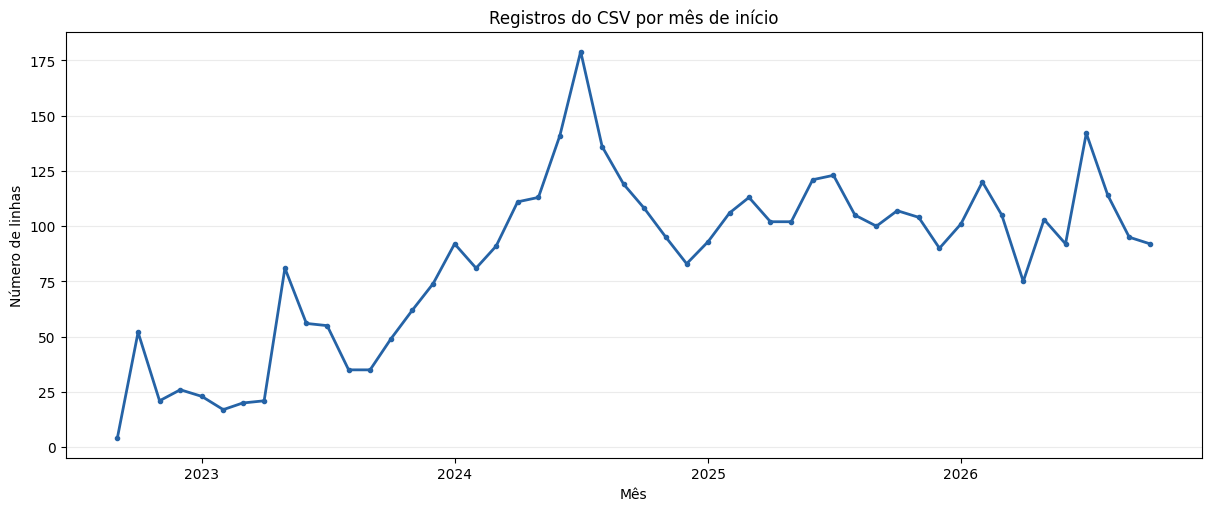

In [126]:
# Biblioteca de gráficos. A dependência está listada em requirements.txt.
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Conta linhas do CSV por mês da data de início.
monthly_records = (
    df_attacks_prepared
    .set_index("time_start_date")
    .resample("MS")
    .size()
)

fig, ax = plt.subplots(figsize=(12, 5), layout="constrained")
ax.plot(
    monthly_records.index,
    monthly_records.values,
    color="#2563a6",
    linewidth=2,
    marker="o",
    markersize=3
)
ax.set_title("Registros do CSV por mês de início")
ax.set_xlabel("Mês")
ax.set_ylabel("Número de linhas")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(axis="y", alpha=0.25)
plt.show()


Use este gráfico para localizar períodos com maior ou menor número de linhas no arquivo. Variações podem refletir tanto os registros disponíveis quanto mudanças na cobertura da base; o gráfico, sozinho, não permite atribuir causas.


### 6.2 Dez modelos mais frequentes

O gráfico de barras horizontais facilita comparar modelos pelo número de linhas associadas a cada rótulo. A ordenação coloca o mais frequente no topo.


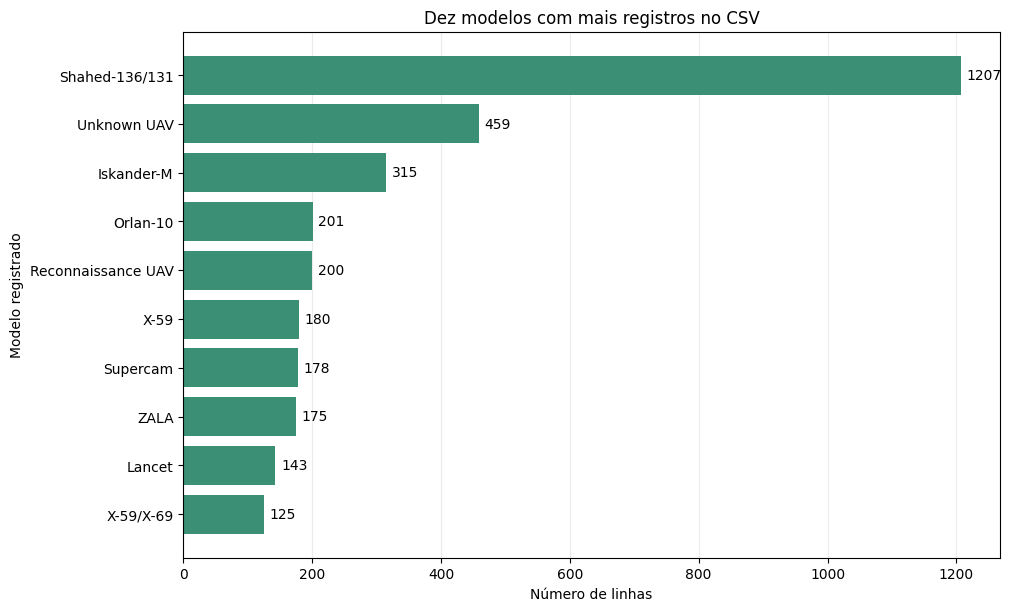

In [127]:
# Reutiliza a frequência por modelo calculada na seção 5.
models_to_plot = top_models["records"].sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
bars = ax.barh(
    models_to_plot.index,
    models_to_plot.values,
    color="#3a8f75"
)
ax.bar_label(bars, padding=4, fmt="%d")
ax.set_title("Dez modelos com mais registros no CSV")
ax.set_xlabel("Número de linhas")
ax.set_ylabel("Modelo registrado")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
plt.show()


O gráfico compara a frequência dos rótulos model. Uma barra maior significa mais linhas com aquele rótulo; não significa, necessariamente, maior quantidade de equipamentos ou maior intensidade de ataques.


### 6.3 Valores lançados e destruídos

O hexbin agrupa os pares de valores de launched e destroyed e usa a cor para mostrar onde há mais registros. A linha tracejada marca os pontos em que os dois valores seriam iguais. Serão incluídas apenas linhas com os dois campos preenchidos.


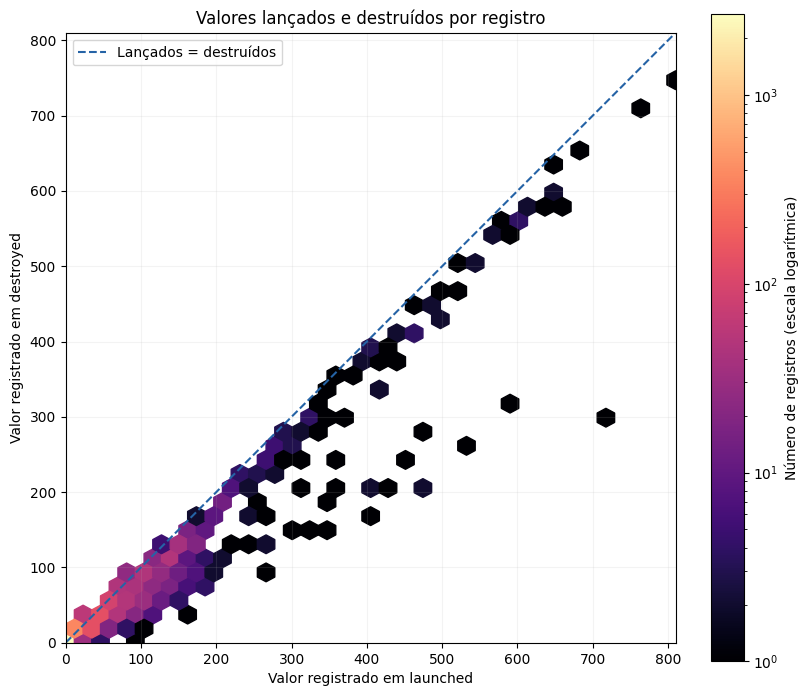

Registros comparados: 4276


In [128]:
# Mantém apenas registros que têm os dois valores para comparação.
paired_counts = df_attacks_prepared[["launched", "destroyed"]].dropna()
axis_max = max(
    paired_counts["launched"].max(),
    paired_counts["destroyed"].max()
)

fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
density = ax.hexbin(
    paired_counts["launched"],
    paired_counts["destroyed"],
    gridsize=35,
    mincnt=1,
    bins="log",
    cmap="magma"
)
ax.plot(
    [0, axis_max],
    [0, axis_max],
    color="#2563a6",
    linestyle="--",
    linewidth=1.5,
    label="Lançados = destruídos"
)
fig.colorbar(density, ax=ax, label="Número de registros (escala logarítmica)")
ax.set_title("Valores lançados e destruídos por registro")
ax.set_xlabel("Valor registrado em launched")
ax.set_ylabel("Valor registrado em destroyed")
ax.set_xlim(0, axis_max)
ax.set_ylim(0, axis_max)
ax.set_aspect("equal", adjustable="box")
ax.legend()
ax.grid(alpha=0.15)
plt.show()

print("Registros comparados:", len(paired_counts))


A densidade mostra onde se concentram os pares de valores. A linha diagonal serve como referência visual, mas a distância até ela não deve ser tratada como uma taxa de eficiência: as categorias e os critérios de registro precisam ser considerados.


### 6.4 Evolução dos valores registrados no JSON

As categorias Personnel e Tanks serão mostradas em painéis separados porque suas escalas são diferentes. A linha clara representa os valores registrados por data; a linha mais escura mostra a média móvel de 30 dias, que suaviza oscilações de curto prazo sem substituir a série original.


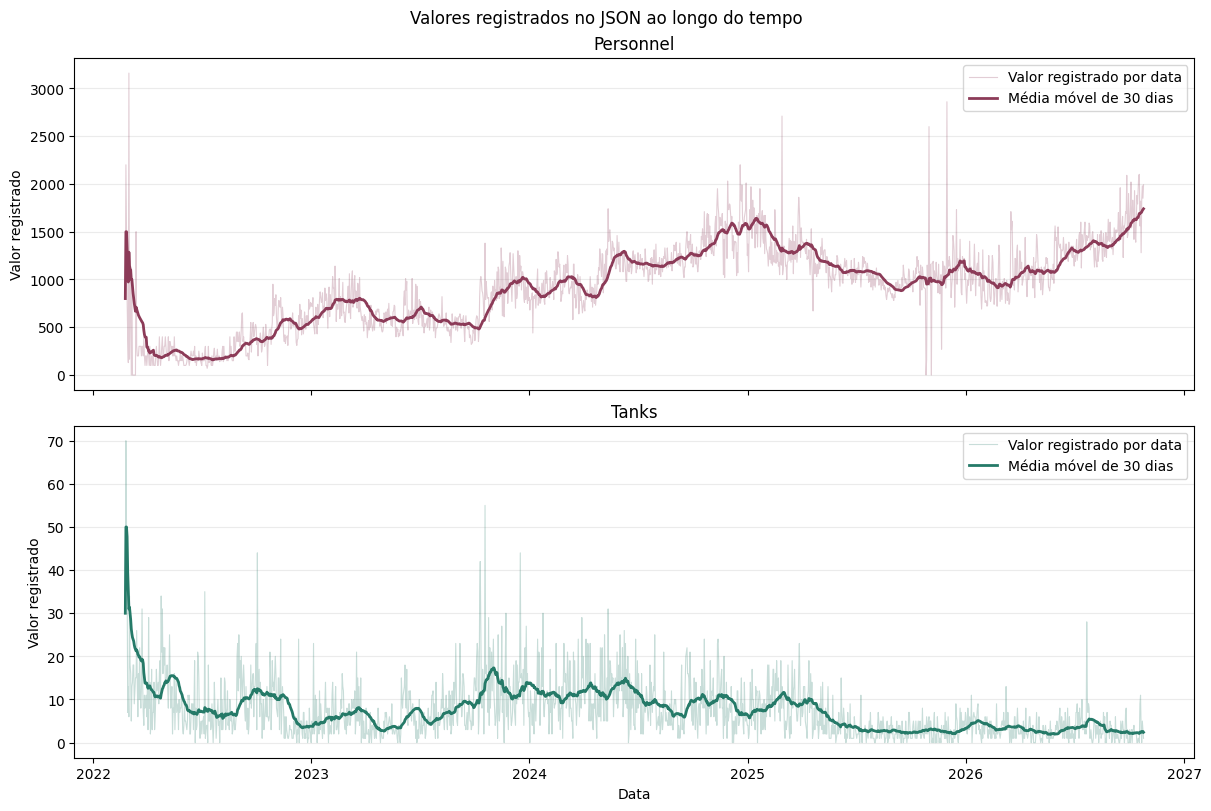

In [129]:
# Organiza os registros do JSON em ordem temporal para a visualização.
losses_by_date = df_losses_prepared.set_index("date").sort_index()
categories_to_plot = ["Personnel", "Tanks"]
colors = {"Personnel": "#8c3b58", "Tanks": "#257a68"}

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12, 8),
    sharex=True,
    layout="constrained"
)

for ax, category in zip(axes, categories_to_plot):
    values = losses_by_date[category]
    rolling_mean = values.rolling(window=30, min_periods=1).mean()

    ax.plot(
        values.index,
        values,
        color=colors[category],
        alpha=0.25,
        linewidth=0.8,
        label="Valor registrado por data"
    )
    ax.plot(
        rolling_mean.index,
        rolling_mean,
        color=colors[category],
        linewidth=2,
        label="Média móvel de 30 dias"
    )
    ax.set_title(category)
    ax.set_ylabel("Valor registrado")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Data")
axes[-1].xaxis.set_major_locator(mdates.YearLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle("Valores registrados no JSON ao longo do tempo")
plt.show()


Os painéis permitem observar a variação temporal de cada categoria sem sobrepor escalas diferentes. A média móvel é apenas um recurso de leitura; ela não altera os dados preparados. Como a origem primária e a metodologia do JSON não estão documentadas nos arquivos locais, descrevemos os valores como registros da base e evitamos interpretá-los como validação independente.


## 7. Principais observações

Esta seção reúne os achados descritivos das etapas anteriores. As observações se referem aos arquivos e às versões analisadas; não estabelecem causalidade nem confirmam, por si só, a precisão dos registros.


### 7.1 Síntese do CSV

Vamos reunir as dimensões, a faixa temporal, os modelos com mais linhas, algumas estatísticas de launched e destroyed e os campos com mais ausências.


In [130]:
# Consolida indicadores descritivos do CSV já preparado.
print("Dimensão original:", df_attacks.shape)
print(
    "Período de time_start:",
    df_attacks_prepared["time_start_date"].min().date(),
    "a",
    df_attacks_prepared["time_start_date"].max().date()
)
print("Modelos com mais registros:")
print(top_models["records"].head(3).to_string())
print(
    "Medianas launched / destroyed:",
    df_attacks_prepared["launched"].median(),
    "/",
    df_attacks_prepared["destroyed"].median()
)
print("Percentual ausente nos campos mais incompletos:")
print(
    (df_attacks.isna().mean().sort_values(ascending=False).head(5) * 100)
    .round(2)
    .to_string()
)


Dimensão original: (4285, 22)
Período de time_start: 2022-09-28 a 2026-10-23
Modelos com mais registros:
model
Shahed-136/131    1207
Unknown UAV        459
Iskander-M         315
Medianas launched / destroyed: 4.0 / 3.0
Percentual ausente nos campos mais incompletos:
launch_place_details    99.84
launched_details        99.84
status_data             99.42
destroyed_types         98.34
target_main             96.48


O CSV possui 4.285 linhas e cobre datas de início de 2022-09-28 a 2026-10-23. Shahed-136/131 é o rótulo mais frequente, em 1.207 linhas. As medianas de launched e destroyed são 4 e 3, respectivamente, enquanto suas médias são bem maiores, mostrando distribuições assimétricas.

Há campos muito incompletos: status_data tem 99,42% de valores ausentes e target_main, 96,48%. Essas ausências limitam as perguntas que podem ser respondidas com esses campos e não foram preenchidas.


### 7.2 Síntese do JSON

Vamos resumir o período, a estrutura das categorias e alguns valores registrados para Personnel, Tanks e UAV.


In [131]:
# Consolida indicadores descritivos do JSON preparado.
print(
    "Período:",
    df_losses_prepared["date"].min().date(),
    "a",
    df_losses_prepared["date"].max().date()
)
print("Número de datas:", len(df_losses_prepared))
print("Número de categorias:", len(losses_json["legend"]))
print("Categorias com valores ausentes:",
      int(df_losses_prepared.drop(columns="date").isna().sum().sum()))
print("Medianas Personnel / Tanks / UAV:")
print(
    df_losses_prepared[["Personnel", "Tanks", "UAV"]]
    .median()
    .to_string()
)


Período: 2022-02-24 a 2026-10-25
Número de datas: 1705
Número de categorias: 15
Categorias com valores ausentes: 0
Medianas Personnel / Tanks / UAV:
Personnel    970.0
Tanks          5.0
UAV           36.0


O JSON cobre 1.705 datas de 2022-02-24 a 2026-10-25 e contém 15 categorias com estrutura completa na versão analisada. As medianas de Personnel, Tanks e UAV são 970, 5 e 36. Como as categorias têm unidades e escalas próprias, esses valores não devem ser comparados como se medissem a mesma coisa.


### 7.3 Limites da interpretação

Os dados locais não documentam completamente a origem primária nem a metodologia de coleta. No CSV, a coluna source contém referências textuais; no JSON, há uma legenda, mas não metadados de autoria. Além disso, o campo is_shahed está armazenado como numérico e apresenta vários valores distintos, apesar do nome sugerir um indicador binário.

Por esses motivos, as conclusões deste notebook são descritivas: resumem o conteúdo disponível, sem validar independentemente os acontecimentos, atribuir causas ou inferir relações entre as bases. As duas bases permaneceram separadas porque suas unidades de observação são diferentes.


### Síntese

A exploração encontrou concentração de registros em poucos rótulos de modelo, distribuição assimétrica nos campos numéricos de lançamentos e destruições e grande volume de ausências em alguns campos do CSV. O JSON tem estrutura diária consistente e categorias completas, mas sua origem primária não está identificada nos arquivos locais. As análises e visualizações devem ser lidas com esses limites em mente.
